In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.subplots import make_subplots
from plotly import graph_objects as go
import plotly.express as px


In [3]:
asset = pd.read_csv('s4_asset_registry.csv',parse_dates=['installation_year'])
tickets = pd.read_csv('s4_maintenance_tickets.csv',parse_dates=['opened_date'])
pressure = pd.read_csv('s4_daily_pressure.csv',parse_dates=['reading_date'])
project = pd.read_csv('s4_capital_projects.csv')
ref = pd.read_csv('s4_zone_reference.csv')

In [35]:
print(asset.asset_id.nunique())
print(tickets.ticket_id.nunique())
print(tickets.resolution_hours.isna().sum())
print(tickets.status.value_counts().to_dict())
print(pressure.zone.value_counts().to_dict())
print("Service Types:", tickets.service_type.value_counts().to_dict())
print(asset.condition_band.value_counts().to_dict())


480
1800
395
{'Closed': 1405, 'Open': 309, 'Escalated': 86}
{'Arada': 90, 'Addis Ketema': 90, 'Akaki Kality': 90, 'Bole': 90, 'Gullele': 90, 'Kirkos': 90, 'Kolfe Keranio': 90, 'Nifas Silk-Lafto': 90}
Service Types: {'Pipe leak': 613, 'Low pressure': 400, 'Meter issue': 307, 'Valve failure': 247, 'Burst main': 142, 'Water quality': 91}
{'Good': 258, 'Monitor': 168, 'Critical': 54}


In [10]:
closed = tickets[tickets.status == 'Closed']
closure = 100 * len(closed) / len(tickets)
print(closure)
median_hours = closed.resolution_hours.median()
median_hours
critical = (asset.condition_band == 'Critical').sum()
print(critical)

78.05555555555556
54


In [11]:
z = tickets.groupby('zone').agg(total = ('ticket_id','count'), 
closed =('status',lambda
 x:(x=='Closed').sum()))
z['shared_pct']= 100 * z.closed / z.total
print(round(z.shared_pct,1).to_dict()),
round(z.shared_pct.max(),1)
z


{'Addis Ketema': 77.6, 'Akaki Kality': 80.4, 'Arada': 74.6, 'Bole': 75.8, 'Gullele': 76.9, 'Kirkos': 78.8, 'Kolfe Keranio': 79.4, 'Nifas Silk-Lafto': 81.1}


,total,closed,shared_pct
zone,,,
Addis Ketema,259,201,77.606178
Akaki Kality,204,164,80.392157
Arada,240,179,74.583333
Bole,194,147,75.773196
Gullele,212,163,76.886792
Kirkos,231,182,78.787879
Kolfe Keranio,233,185,79.399142
Nifas Silk-Lafto,227,184,81.057269


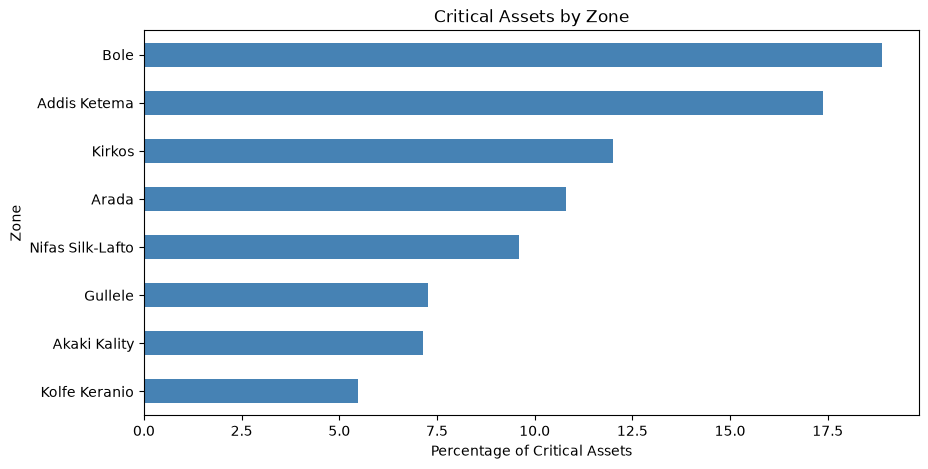

In [12]:
a = asset.groupby('zone').agg(total = ('asset_id','count'),
critical =('condition_band',lambda x:(x=='Critical').sum()))
a['critical_pct']= 100 * a.critical / a.total
a.sort_values('critical_pct')['critical_pct'].plot(kind='barh',
figsize=(10,5),title='Critical Assets by Zone',color='steelblue',align='center')
plt.xlabel('Percentage of Critical Assets')
plt.ylabel('Zone')

#a.critical(right=15)  # adjust xlim to fit labels

plt.show()

In [49]:
a

,total,critical,critical_pct
zone,,,
Addis Ketema,46,8,17.391304
Akaki Kality,56,4,7.142857
Arada,37,4,10.810811
Bole,90,17,18.888889
Gullele,55,4,7.272727
Kirkos,50,6,12.000000
Kolfe Keranio,73,4,5.479452
Nifas Silk-Lafto,73,7,9.589041


In [24]:
z = tickets.groupby('zone').agg(
  total=('ticket_id', 'count'),
  closed=('status',
lambda s:(s=='Closed').sum()))
# Calculate closure percentage
z['closure_pct'] = 100 * z.closed / z.total

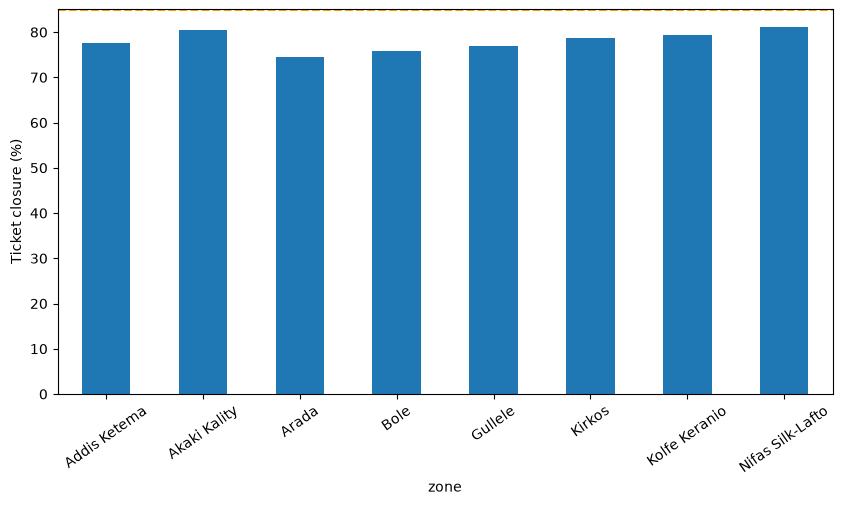

In [25]:
import matplotlib.pyplot as plt
z.closure_pct.plot(kind='bar', figsize=(10,5))
plt.axhline(85, ls='--', color='orange')
plt.ylabel('Ticket closure (%)')
plt.xticks(rotation=35)
plt.show()

In [14]:
closed = tickets[tickets.status=='Closed']
med = closed.groupby('priority')[
'resolution_hours'].median().round(1)
print(med.to_string())

priority
High      24.3
Low       24.6
Medium    23.2
Urgent    15.2


In [15]:
pressure['reading_date'] = pd.to_datetime(
    pressure['reading_date'])
daily = pressure.groupby('reading_date')[
'pressure_m'].mean().reset_index()
print(len(daily), 
round(daily.pressure_m.mean(),1))

90 37.5


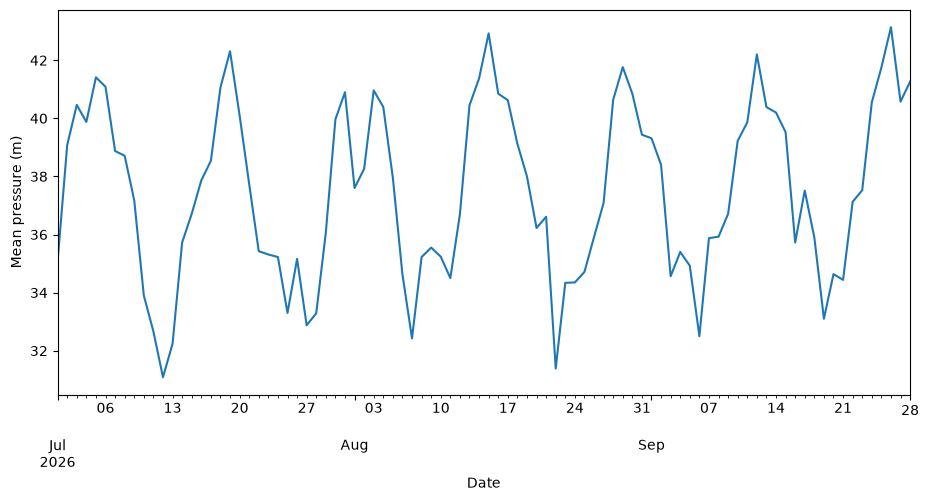

In [16]:
import matplotlib.pyplot as plt
daily.plot(x='reading_date', y='pressure_m',
           figsize=(11,5), legend=False)
plt.ylabel('Mean pressure (m)')
plt.xlabel('Date')
plt.show()

In [17]:
q = project.groupby('project_type')[[
'planned_progress_pct',
'actual_progress_pct'
]].mean().round(1)
print(q.shape)
q

(4, 2)


,planned_progress_pct,actual_progress_pct
project_type,,
Network extension,58.6,49.4
Pipe replacement,60.4,57.0
Pump upgrade,62.2,54.7
Reservoir maintenance,63.3,53.6


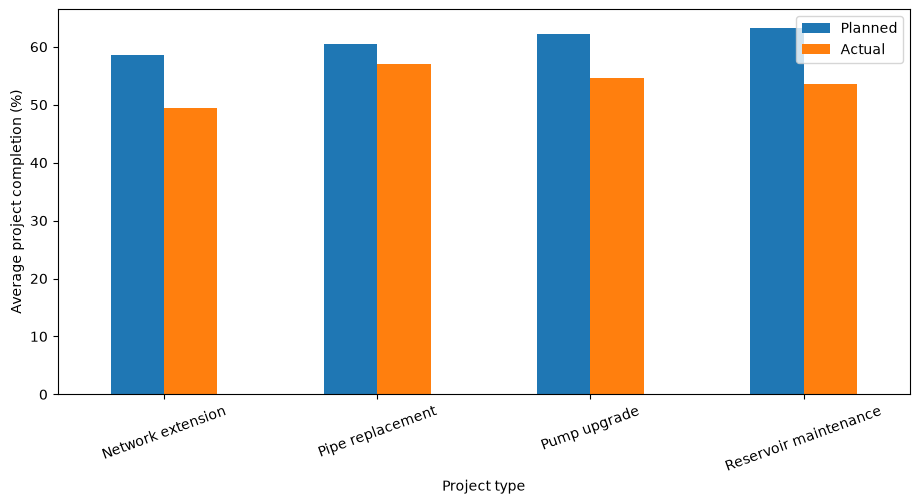

In [18]:
q.plot(kind='bar', figsize=(11,5))
plt.ylabel('Average project completion (%)')
plt.xlabel('Project type')
plt.xticks(rotation=20)
plt.legend(['Planned', 'Actual'])
plt.show()

In [19]:
az = asset.groupby('zone').size().rename('assets')
tz = tickets.groupby('zone').size().rename('tickets')
pz = pressure.groupby('zone')['pressure_m'].mean().rename('pressure_m')
summary = pd.concat([az,tz,pz], axis=1)

In [20]:
summary = summary.join(
ref.set_index('zone')['service_population'])
summary['tickets_per_10k'] = (
summary.tickets / summary.service_population * 
10000)
print(summary.shape)

(8, 5)


In [21]:
print(summary[['assets','tickets',
'pressure_m']].head(2).round(1).to_string())

              assets  tickets  pressure_m
zone                                     
Addis Ketema      46      259        39.7
Akaki Kality      56      204        29.0


In [29]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import kaleido
fig = make_subplots(rows=1, cols=2,
subplot_titles=['Closure %', 'Critical assets %'])
fig.add_trace(go.Bar(x=z.index,
y=z.closure_pct), row=1, col=1)
fig.add_trace(go.Bar(x=a.index,
y=a.critical_pct), row=1, col=2)
fig.update_layout(title='Service & Asset Overview',showlegend=False, height=550)
#fig.show()
fig.write_html('s4_dashboard.html')
fig.write_image('s4_dashboard.png')
